# <a id='toc1_'></a>[Análise e tratamento](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Análise e tratamento](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
  - [Análise de redundância](#toc1_3_)    
    - [Análise da distribuição](#toc1_3_1_)    
    - [Matriz de correlação](#toc1_3_2_)    
  - [Conclusão](#toc1_4_)    
  - [Referências](#toc1_5_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Nesse notebook, iremos analisar o conjunto de dados obtidos e aplicar alguns tratamentos essenciais para garantir a implementação adequada do dataset aos modelos, evitando vazamento de dados ou desequilíbrios.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

Vamos começar carregando os dados obtidos

In [52]:
import pandas as pd

df_earthquakes = pd.read_csv("Data/earthquake_dataset.csv")
df_earthquakes

,event_id,latitude,longitude,epicenter_distance,geodesic_distance,azimuth_degree,magnitude,magnitude_type,depth,origin_time,...,min_noise,max_noise,noise_std,noise_region,min_amplitude,max_amplitude,amplitude_std,amplitude_region,std_factor,amplitude_factor
0,Panama2026-10-09T20:25:39.395890Z,7.671206,-81.304634,45.301436,5.028941e+06,132.938933,6.298313,mb,10.000000,2026-10-09T20:25:39.395890Z,...,0.124038,193.039506,37.481475,"{'x0': np.float64(1791576237.0), 'x1': np.floa...",0.000000,458.941231,87.864057,"{'x0': 1791577977.1918666, 'x1': 1791580845.70...",2.344200,2.378976
1,Panama2026-10-09T20:21:41.592678Z,7.145816,-80.153854,44.111292,4.896569e+06,133.493594,5.118514,mb,12.480278,2026-10-09T20:21:41.592678Z,...,0.124038,241.935745,43.567619,"{'x0': np.float64(1791575990.0), 'x1': np.floa...",0.000000,458.941231,88.054428,"{'x0': 1791577729.5039217, 'x1': 1791580608.36...",2.021098,1.897928
2,Panama2026-10-09T20:20:23.889385Z,7.908816,-80.532303,44.910195,4.985018e+06,133.739742,4.840052,mb,10.000000,2026-10-09T20:20:23.889385Z,...,0.124038,241.935745,44.689854,"{'x0': np.float64(1791575919.0), 'x1': np.floa...",0.000000,458.941231,88.176270,"{'x0': 1791577658.5746796, 'x1': 1791580530.59...",1.973071,1.897928
3,Panama2026-10-09T19:48:56.323765Z,7.530637,-81.143005,45.088416,5.005294e+06,132.967242,5.288268,mb,4.654874,2026-10-09T19:48:56.323765Z,...,0.227360,384.157055,75.241967,"{'x0': np.float64(1791574033.0), 'x1': np.floa...",0.075447,309.042894,44.185110,"{'x0': 1791575773.265748, 'x1': 1791578644.442...",0.587240,0.804750
4,South of Panama2026-10-09T19:46:01.019697Z,7.275383,-79.672798,43.857442,4.868093e+06,133.993399,5.149563,mb,10.000000,2026-10-09T19:46:01.019697Z,...,0.227360,384.157055,79.849409,"{'x0': np.float64(1791573847.0), 'x1': np.floa...",0.075447,309.042894,44.641111,"{'x0': 1791575587.2811751, 'x1': 1791578468.78...",0.559066,0.804750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,Near Coast of Central Chile2024-11-26T12:33:09...,-30.401300,-71.173592,22.808121,2.539193e+06,76.456117,5.446261,mb,48.000000,2024-11-26T12:33:09.958287Z,...,0.142974,496.921499,75.107197,"{'x0': np.float64(1732622889.0), 'x1': np.floa...",0.000000,1178.805075,220.248041,"{'x0': 1732624628.546917, 'x1': 1732627703.842...",2.932449,2.372899
498,Mexico-Guatemala Border Region2026-07-30T06:58...,15.174971,-91.834534,57.993947,6.438937e+06,129.846115,5.316572,mb,10.000000,2026-07-30T06:58:37.577936Z,...,0.000000,106.780733,24.575542,"{'x0': np.float64(1785393510.0), 'x1': np.floa...",0.000000,109.318150,24.407343,"{'x0': 1785395250.312718, 'x1': 1785398009.335...",0.993156,1.023763
499,Chile-Bolivia Border Region2025-04-08T22:30:42...,-20.931959,-68.391380,19.874477,2.213332e+06,99.332177,5.035261,mb,109.750999,2025-04-08T22:30:42.814313Z,...,0.000000,56993.787540,12922.268671,"{'x0': np.float64(1744149905.0), 'x1': np.floa...",0.000000,61228.633914,13392.960661,"{'x0': 1744151645.282747, 'x1': 1744154744.378...",1.036425,1.074304
500,Southern Bolivia2025-05-29T16:48:08.214941Z,-21.329615,-66.884544,18.424548,2.051905e+06,98.283805,5.020650,mb,213.626007,2025-05-29T16:48:08.214941Z,...,0.000000,55814.158688,12151.015261,"{'x0': np.float64(1748535728.0), 'x1': np.floa...",0.000000,56969.870858,12547.899748,"{'x0': 1748537467.6362522, 'x1': 1748540567.38...",1.032663,1.020706


## <a id='toc1_3_'></a>[Análise de redundância](#toc0_)

Como utilizamos diferentes filtros para buscar terremotos (logs, magnitude e localidade), pode ser que obtivemos o mesmo log mais de uma vez. Vamos começar removendo as observações duplicadas da nossa tabela com base no `event_id`.

In [53]:
df_earthquakes = df_earthquakes.drop_duplicates(subset="event_id")
df_earthquakes

,event_id,latitude,longitude,epicenter_distance,geodesic_distance,azimuth_degree,magnitude,magnitude_type,depth,origin_time,...,min_noise,max_noise,noise_std,noise_region,min_amplitude,max_amplitude,amplitude_std,amplitude_region,std_factor,amplitude_factor
0,Panama2026-10-09T20:25:39.395890Z,7.671206,-81.304634,45.301436,5.028941e+06,132.938933,6.298313,mb,10.000000,2026-10-09T20:25:39.395890Z,...,0.124038,193.039506,37.481475,"{'x0': np.float64(1791576237.0), 'x1': np.floa...",0.000000,458.941231,87.864057,"{'x0': 1791577977.1918666, 'x1': 1791580845.70...",2.344200,2.378976
1,Panama2026-10-09T20:21:41.592678Z,7.145816,-80.153854,44.111292,4.896569e+06,133.493594,5.118514,mb,12.480278,2026-10-09T20:21:41.592678Z,...,0.124038,241.935745,43.567619,"{'x0': np.float64(1791575990.0), 'x1': np.floa...",0.000000,458.941231,88.054428,"{'x0': 1791577729.5039217, 'x1': 1791580608.36...",2.021098,1.897928
2,Panama2026-10-09T20:20:23.889385Z,7.908816,-80.532303,44.910195,4.985018e+06,133.739742,4.840052,mb,10.000000,2026-10-09T20:20:23.889385Z,...,0.124038,241.935745,44.689854,"{'x0': np.float64(1791575919.0), 'x1': np.floa...",0.000000,458.941231,88.176270,"{'x0': 1791577658.5746796, 'x1': 1791580530.59...",1.973071,1.897928
3,Panama2026-10-09T19:48:56.323765Z,7.530637,-81.143005,45.088416,5.005294e+06,132.967242,5.288268,mb,4.654874,2026-10-09T19:48:56.323765Z,...,0.227360,384.157055,75.241967,"{'x0': np.float64(1791574033.0), 'x1': np.floa...",0.075447,309.042894,44.185110,"{'x0': 1791575773.265748, 'x1': 1791578644.442...",0.587240,0.804750
4,South of Panama2026-10-09T19:46:01.019697Z,7.275383,-79.672798,43.857442,4.868093e+06,133.993399,5.149563,mb,10.000000,2026-10-09T19:46:01.019697Z,...,0.227360,384.157055,79.849409,"{'x0': np.float64(1791573847.0), 'x1': np.floa...",0.075447,309.042894,44.641111,"{'x0': 1791575587.2811751, 'x1': 1791578468.78...",0.559066,0.804750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,Near Coast of Central Chile2024-11-26T12:33:09...,-30.401300,-71.173592,22.808121,2.539193e+06,76.456117,5.446261,mb,48.000000,2024-11-26T12:33:09.958287Z,...,0.142974,496.921499,75.107197,"{'x0': np.float64(1732622889.0), 'x1': np.floa...",0.000000,1178.805075,220.248041,"{'x0': 1732624628.546917, 'x1': 1732627703.842...",2.932449,2.372899
498,Mexico-Guatemala Border Region2026-07-30T06:58...,15.174971,-91.834534,57.993947,6.438937e+06,129.846115,5.316572,mb,10.000000,2026-07-30T06:58:37.577936Z,...,0.000000,106.780733,24.575542,"{'x0': np.float64(1785393510.0), 'x1': np.floa...",0.000000,109.318150,24.407343,"{'x0': 1785395250.312718, 'x1': 1785398009.335...",0.993156,1.023763
499,Chile-Bolivia Border Region2025-04-08T22:30:42...,-20.931959,-68.391380,19.874477,2.213332e+06,99.332177,5.035261,mb,109.750999,2025-04-08T22:30:42.814313Z,...,0.000000,56993.787540,12922.268671,"{'x0': np.float64(1744149905.0), 'x1': np.floa...",0.000000,61228.633914,13392.960661,"{'x0': 1744151645.282747, 'x1': 1744154744.378...",1.036425,1.074304
500,Southern Bolivia2025-05-29T16:48:08.214941Z,-21.329615,-66.884544,18.424548,2.051905e+06,98.283805,5.020650,mb,213.626007,2025-05-29T16:48:08.214941Z,...,0.000000,55814.158688,12151.015261,"{'x0': np.float64(1748535728.0), 'x1': np.floa...",0.000000,56969.870858,12547.899748,"{'x0': 1748537467.6362522, 'x1': 1748540567.38...",1.032663,1.020706


Vemos que nosso conjunto diminuiu de 502 observações para 476, ou seja, 27 terremotos duplicados que foram deletados.

Além dos terremotos exatamente iguais, também existem aqueles que são muito parecidos. No nosso caso, temos vários terremotos que se originaram em um intervalo de tempo e localidade muito próximos, atingindo o Sirius em tempos muito semelhantes. Nossa análise, entretanto, não consegue distinguir a contribuição de cada um dos terremotos, então ambos dizem respeito, praticamente, à mesma faixa temporal do sinal.

Isso pode gerar redundância nos nossos dados, o que acarretaria em um possível vazamento de dados. Para evitar isso, vamos buscar esses terremotos com semelhança temporal e manteremos o terromoto com o menor tempo de início entre aqueles que entraram em conflito.

In [54]:
import numpy as np

def _to_seconds(value):
    if isinstance(value, (int, float, np.integer, np.floating)):
        return float(value)
    stamp = getattr(value, "timestamp", None)
    if stamp is not None:
        return float(stamp() if callable(stamp) else stamp)
    return pd.Timestamp(value).timestamp()

df_earthquakes["first_arrival"] = (
    df_earthquakes["origin_time"].apply(_to_seconds)
    + df_earthquakes["first_arrival_time_delta"]
)

df_earthquakes["last_arrival"] = (
    df_earthquakes["first_arrival"]
    + df_earthquakes["arrival_time_delta"]
)

df_earthquakes = df_earthquakes.sort_values("first_arrival").copy()

selected = []
last_arrival = -np.inf

for _, row in df_earthquakes.iterrows():
    if row["first_arrival"] >= last_arrival:
        selected.append(row)
        last_arrival = row["last_arrival"]

df_earthquakes = pd.DataFrame(selected).reset_index(drop=True)

df_earthquakes

C:\Users\filipi2610041\AppData\Local\Temp\ipykernel_37380\2732247082.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_earthquakes["first_arrival"] = (
C:\Users\filipi2610041\AppData\Local\Temp\ipykernel_37380\2732247082.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_earthquakes["last_arrival"] = (


,event_id,latitude,longitude,epicenter_distance,geodesic_distance,azimuth_degree,magnitude,magnitude_type,depth,origin_time,...,noise_std,noise_region,min_amplitude,max_amplitude,amplitude_std,amplitude_region,std_factor,amplitude_factor,first_arrival,last_arrival
0,Cuba Region2020-01-28T19:10:22.861893Z,19.339197,-78.801216,52.318245,5.800753e+06,142.025918,7.547371,Mwp,0.000000,2020-01-28T19:10:22.861893Z,...,10773.287036,"{'x0': np.float64(1580237376.0), 'x1': np.floa...",0.0,27236.564300,1377.535261,"{'x0': 1580239116.1732109, 'x1': 1580241924.49...",0.127866,0.611030,1.580239e+09,1.580242e+09
1,Kuril Islands2020-02-13T10:33:38.812968Z,45.465420,149.276504,153.733322,1.709241e+07,35.499121,7.017215,mB,121.251366,2020-02-13T10:33:38.812968Z,...,11375.311445,"{'x0': np.float64(1581589268.0), 'x1': np.floa...",0.0,50948.537640,11216.897473,"{'x0': 1581591008.3566542, 'x1': 1581595453.0,...",0.986074,1.066733,1.581591e+09,1.581595e+09
2,East of Kuril Islands2020-03-25T02:49:11.159690Z,49.006786,158.678940,146.856493,1.632796e+07,46.754932,7.604934,mB,10.000000,2020-03-25T02:49:11.159690Z,...,0.001342,"{'x0': np.float64(1585103784.0), 'x1': np.floa...",0.0,0.006025,0.001362,"{'x0': 1585105524.2211037, 'x1': 1585109766.0,...",1.014633,1.031189,1.585106e+09,1.585110e+09
3,South of Kermadec Islands2020-06-18T12:49:53.2...,-33.407040,-178.260696,107.069040,1.192499e+07,133.584818,7.312320,mB,10.000000,2020-06-18T12:49:53.203849Z,...,4516.930182,"{'x0': np.float64(1592483650.0), 'x1': np.floa...",0.0,24523.256959,2185.540188,"{'x0': 1592485389.6519437, 'x1': 1592488009.0,...",0.483855,0.948059,1.592485e+09,1.592488e+09
4,"Oaxaca, Mexico2020-06-23T15:29:05.856787Z",16.016554,-95.881226,61.554104,6.835611e+06,127.712764,7.411209,mB,38.273556,2020-06-23T15:29:05.856787Z,...,257.075331,"{'x0': np.float64(1592924959.0), 'x1': np.floa...",0.0,1744.718093,337.400559,"{'x0': 1592926699.0376651, 'x1': 1592929425.27...",1.312458,1.170427,1.592927e+09,1.592929e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
439,Southern Mid-Atlantic Ridge2026-10-13T08:38:28...,-28.499863,-12.648232,31.421167,3.499362e+06,272.389218,5.282686,mb,0.000000,2026-10-13T08:38:28.868149Z,...,13076.930022,"{'x0': np.float64(1791879292.0), 'x1': np.floa...",0.0,59093.897848,13071.317397,"{'x0': 1791881031.6703076, 'x1': 1791884030.24...",0.999571,1.001455,1.791881e+09,1.791884e+09
440,Off Coast of Ecuador2026-10-16T19:34:13.063601Z,1.210575,-85.026466,44.085385,4.899086e+06,125.222618,5.227027,mb,10.000000,2026-10-16T19:34:13.063601Z,...,24.259587,"{'x0': np.float64(1792177941.0), 'x1': np.floa...",0.0,119.632126,25.131914,"{'x0': 1792179681.1553068, 'x1': 1792182560.59...",1.035958,1.041796,1.792180e+09,1.792183e+09
441,Solomon Islands2026-10-24T02:31:13.659376Z,-8.499777,157.692154,140.415230,1.562654e+07,142.953590,7.006438,Mwp,10.000000,2026-10-24T02:31:13.659376Z,...,25.268288,"{'x0': np.float64(1792808278.0), 'x1': np.floa...",0.0,132.865801,28.991444,"{'x0': 1792810018.128538, 'x1': 1792813530.0, ...",1.147345,1.109488,1.792810e+09,1.792813e+09
442,Bouvet Island Region2026-10-24T15:24:26.259182Z,-53.687351,6.795708,50.625117,5.634061e+06,285.550006,5.949712,mb,43.653282,2026-10-24T15:24:26.259182Z,...,26.656059,"{'x0': np.float64(1792854201.0), 'x1': np.floa...",0.0,119.316019,25.279636,"{'x0': 1792855940.7418182, 'x1': 1792858757.95...",0.948364,0.997025,1.792856e+09,1.792859e+09


Agora descemos de 476 para 444 observações, i.e. 32 linhas redundantes no nosso dataset.

### <a id='toc1_3_1_'></a>[Análise da distribuição](#toc0_)

Vamos analisar a distribuição do nosso target:

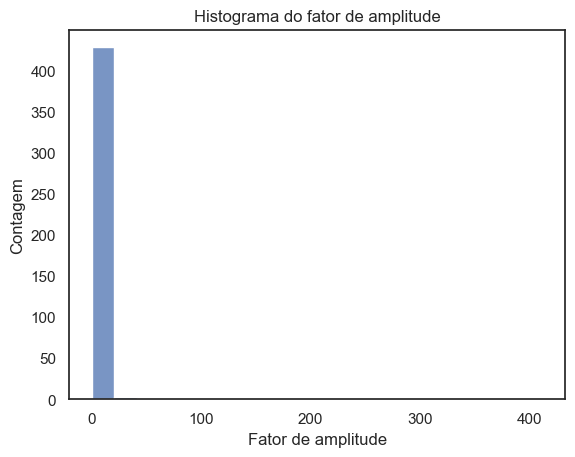

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.histplot(df_earthquakes["amplitude_factor"], bins = 20)
ax.set_title("Histograma do fator de amplitude")
ax.set_xlabel("Fator de amplitude")
ax.set_ylabel("Contagem")

plt.show()

Parece que temos uma distribuição bem assimétrica, centrada em valores pequenos e com uma cauda muito longa. Vamos visualizar essa distribuição em uma escala logarítmica.

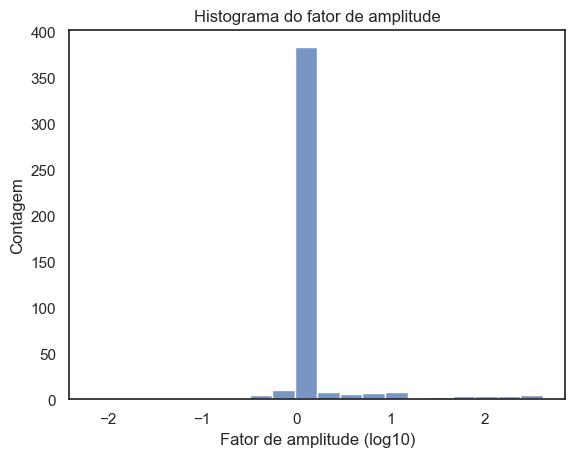

In [56]:
df_earthquakes["amplitude_factor_log10"] = 0.0

mask = df_earthquakes["amplitude_factor"] != 0

df_earthquakes.loc[mask, "amplitude_factor_log10"] = np.log10(
    df_earthquakes.loc[mask, "amplitude_factor"]
)

ax = sns.histplot(df_earthquakes["amplitude_factor_log10"], bins = 20)
ax.set_title("Histograma do fator de amplitude")
ax.set_xlabel("Fator de amplitude (log10)")
ax.set_ylabel("Contagem")

plt.show()

Vemos que muitas das observações variam pouco a amplitudo geral, o que faz sentido.

Vamos analisar como os diferentes percentis se comportam.

In [57]:
df_earthquakes["amplitude_factor"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

count    444.000000
mean       6.976609
std       35.760722
min        0.000000
1%         0.388811
5%         0.983426
25%        1.002587
50%        1.017884
75%        1.056494
95%       10.156716
99%      223.442082
max      412.282523
Name: amplitude_factor, dtype: float64

Observamos uma forte assimetria positiva na distribuição do fator de amplitude. A mediana e os quartis estão concentrados próximos de 1, enquanto os valores acima do percentil 95 aumentam rapidamente, atingindo valores superiores a 400. Essa diferença entre as medidas de tendência central e os valores extremos indica a presença de uma cauda longa à direita, que pode influenciar significativamente métricas baseadas no erro quadrático.

Vamos salvar os dados tratados em um novo arquivo

In [58]:
df_earthquakes.to_csv("Data/earthquake_dataset_treated.csv", index=False)

### <a id='toc1_3_2_'></a>[Matriz de correlação](#toc0_)

Para identificarmos as correlções presentes entre os nossos atributos, podemos visualizar a matriz de correlações.

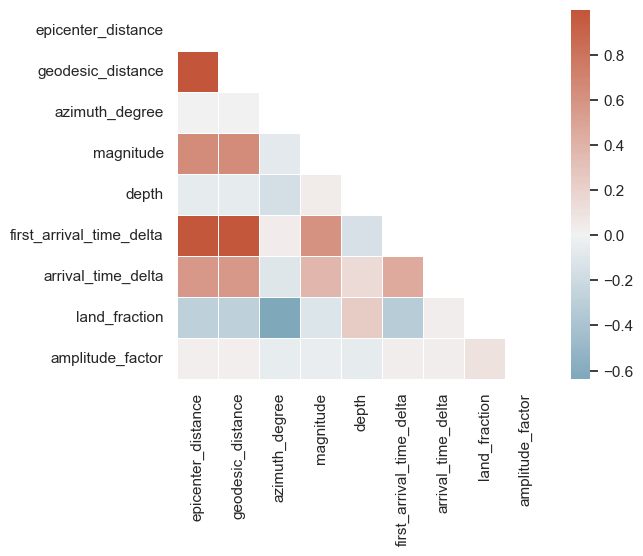

In [59]:
import seaborn as sns
import numpy as np

COLUMNS = [
    "epicenter_distance",
    "geodesic_distance",
    "azimuth_degree",
    "magnitude",
    "depth",
    "first_arrival_time_delta",
    "arrival_time_delta",
    "land_fraction",
    "amplitude_factor"
]

corr_matrix = df_earthquakes[COLUMNS].corr()

sns.set_theme(style="white")

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap=cmap,
    center=0,
    square=True,
    linewidths=0.5,
);


Podemos ver que as distâncias e os tempos de chegada estão diretamente relacionados (o que faz sentido, afinal, quanto mais longe, mais se demora pra chegar, normalmente).

A razão terra/água parece ser inversamente proporcional às medidas de tempo e distância, enquanto a última linha, que é o nosso target, não parece apresentar nenhum tipo de correlação predominante com o resto dos dados.

## <a id='toc1_4_'></a>[Conclusão](#toc0_)

Dessa forma, conseguimos tratar a redundância inicial dos nossos dados e percebemos que nosso target está distribuído de forma assimétrica. Vamos precisar considerar isso na hora de testar nossos modelos.

<span id="referencias"></span>
## <a id='toc1_5_'></a>[Referências](#toc0_)

1. **CASSAR, Daniel R.** *ATP-203 6.1 - Vazamento de dados*. Campinas: Ilum Escola de Ciência, 2026.